# Deep Learning Model: 1D-CNN

## TRUST-XIDS — Notebook 5

Implements and evaluates the mandatory fourth model — a 1D Convolutional
Neural Network — using the same experiment structure and evaluation
protocol as Notebook 4, so results stay directly comparable across all
four models.

A 1D-CNN applied to tabular flow features treats the feature vector as a
fixed-length sequence and learns local patterns across *adjacent feature
positions in the chosen ordering* — it is not learning temporal structure
in network traffic over time, since a single row here is one flow's
summary statistics, not a time series. Whether this kind of local-pattern
learning helps on this feature ordering is an empirical question this
notebook answers, not an assumption.

# 1. Import Libraries

In [2]:
import os
import json
import time

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, classification_report
)

BASE_DIR = r"C:\Users\Anu\OneDrive\Desktop\IDS"
PROCESSED_DIR = os.path.join(BASE_DIR, "data/processed")
MODELS_DIR = os.path.join(BASE_DIR, "models")

RANDOM_STATE = 42
tf.random.set_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

print("TensorFlow version:", tf.__version__)
print("GPU available      :", len(tf.config.list_physical_devices("GPU")) > 0)

TensorFlow version: 2.15.1
GPU available      : False


**Note on hardware:** this notebook does not assume a GPU is present —
TensorFlow will use the CPU automatically if no GPU is found, which is
reflected above. CPU training is slower, so epoch count and batch size
below are chosen with that in mind rather than assuming Colab's/your
machine's accelerator.

# 2. Load Data and Feature Metadata

In [3]:
with open(os.path.join(PROCESSED_DIR, "feature_metadata.json")) as f:
    feature_metadata = json.load(f)

unsw_feature_cols = feature_metadata["unsw_final_feature_cols"]
cic_feature_cols = feature_metadata["cic_final_feature_cols"]
common_feature_cols = feature_metadata["common_feature_cols"]

unsw_train = pd.read_csv(os.path.join(PROCESSED_DIR, "unsw_train_selected.csv"))
unsw_test = pd.read_csv(os.path.join(PROCESSED_DIR, "unsw_test_selected.csv"))
cic_train = pd.read_csv(os.path.join(PROCESSED_DIR, "cicids_train_selected.csv"))
cic_test = pd.read_csv(os.path.join(PROCESSED_DIR, "cicids_test_selected.csv"))

unsw_train_harm = pd.read_csv(os.path.join(PROCESSED_DIR, "unsw_train_harmonized.csv"))
unsw_test_harm = pd.read_csv(os.path.join(PROCESSED_DIR, "unsw_test_harmonized.csv"))
cic_train_harm = pd.read_csv(os.path.join(PROCESSED_DIR, "cicids_train_harmonized.csv"))
cic_test_harm = pd.read_csv(os.path.join(PROCESSED_DIR, "cicids_test_harmonized.csv"))

print("Loaded all datasets.")

Loaded all datasets.


# 3. Input Preparation

The feature order is fixed to the order saved by Notebook 3 (`unsw_feature_cols` / `cic_feature_cols` / `common_feature_cols`)
and never re-sorted afterward, since a 1D-CNN's learned filters are
position-specific — reordering columns between train and inference would
silently corrupt predictions even though the model would still run without
error.

Scaling is fit on training data only (own scaler per dataset/experiment,
same leakage-safety rule as every other model in this project), and the
target label is excluded from the feature tensor before scaling.

In [4]:
def prepare_cnn_inputs(X_train_df, y_train, X_test_df, y_test, feature_order):
    X_train_df = X_train_df[feature_order]
    X_test_df = X_test_df[feature_order]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_df)
    X_test_scaled = scaler.transform(X_test_df)

    # 1D-CNN expects (samples, timesteps, channels) - one channel, timesteps = n_features
    X_train_cnn = X_train_scaled.reshape(X_train_scaled.shape[0], X_train_scaled.shape[1], 1)
    X_test_cnn = X_test_scaled.reshape(X_test_scaled.shape[0], X_test_scaled.shape[1], 1)

    return X_train_cnn, y_train.values, X_test_cnn, y_test.values, scaler

print("Input-preparation helper defined.")

Input-preparation helper defined.


# 4. Model Architecture

A small, documented architecture — two convolutional blocks with
batch-normalization and dropout for regularization, global pooling instead
of a flatten layer (keeps the parameter count reasonable regardless of
input width, which matters since UNSW's 33 features and CICIDS's 56
features/8 harmonized features all need to share this same architecture
function), and a single sigmoid output for binary classification.

In [5]:
def build_1d_cnn(input_length, random_state=RANDOM_STATE):
    tf.random.set_seed(random_state)

    model = keras.Sequential([
        layers.Input(shape=(input_length, 1)),

        layers.Conv1D(filters=32, kernel_size=3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling1D(pool_size=2),
        layers.Dropout(0.2),

        layers.Conv1D(filters=64, kernel_size=3, padding="same", activation="relu"),
        layers.BatchNormalization(),
        layers.GlobalAveragePooling1D(),
        layers.Dropout(0.3),

        layers.Dense(32, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(1, activation="sigmoid"),
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

print("Architecture function defined.")
print(build_1d_cnn(33).summary())

Architecture function defined.


Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv1d (Conv1D)             (None, 33, 32)            128       
                                                                 
 batch_normalization (Batch  (None, 33, 32)            128       
 Normalization)                                                  
                                                                 
 max_pooling1d (MaxPooling1  (None, 16, 32)            0         
 D)                                                              
                                                                 
 dropout (Dropout)           (None, 16, 32)            0         
                                                                 
 conv1d_1 (Conv1D)           (None, 16, 64)            6208      
                                                                 
 batch_normalization_1 

# 5. Training and Evaluation Helper

Early stopping on validation loss (patience=5, restoring the best weights)
is the defensible stopping strategy here — it avoids training a fixed,
arbitrary number of epochs regardless of whether the model has already
converged or started overfitting, and the model selected is never chosen
by looking at test-set performance, only the held-out validation split
carved out of the training data.

In [6]:
all_cnn_results = []

def train_and_evaluate_cnn(X_train_df, y_train, X_test_df, y_test, feature_order, experiment_name, epochs=30, batch_size=512):
    X_train_cnn, y_train_arr, X_test_cnn, y_test_arr, scaler = prepare_cnn_inputs(
        X_train_df, y_train, X_test_df, y_test, feature_order
    )

    model = build_1d_cnn(input_length=X_train_cnn.shape[1])

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True
    )

    t0 = time.time()
    history = model.fit(
        X_train_cnn, y_train_arr,
        validation_split=0.1,
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[early_stop],
        verbose=0
    )
    train_seconds = time.time() - t0

    t0 = time.time()
    y_proba = model.predict(X_test_cnn, verbose=0).ravel()
    predict_seconds = time.time() - t0
    y_pred = (y_proba >= 0.5).astype(int)

    metrics = {
        "model": "1D-CNN",
        "experiment": experiment_name,
        "accuracy": accuracy_score(y_test_arr, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_test_arr, y_pred),
        "precision": precision_score(y_test_arr, y_pred, zero_division=0),
        "recall": recall_score(y_test_arr, y_pred, zero_division=0),
        "f1": f1_score(y_test_arr, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test_arr, y_proba),
        "train_seconds": round(train_seconds, 2),
        "predict_seconds": round(predict_seconds, 4),
        "epochs_run": len(history.history["loss"]),
    }

    print(f"1D-CNN - {experiment_name}")
    for k in ["accuracy", "balanced_accuracy", "precision", "recall", "f1", "roc_auc"]:
        print(f"  {k:18s}: {round(metrics[k], 4)}")
    print("  epochs run (early stopping):", metrics["epochs_run"], "/", epochs)
    print("  train time (s)             :", metrics["train_seconds"])
    print()
    print(classification_report(y_test_arr, y_pred, target_names=["Normal", "Attack"], zero_division=0))

    cm = confusion_matrix(y_test_arr, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"])
    plt.title(f"1D-CNN: {experiment_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    plt.figure(figsize=(6, 4))
    plt.plot(history.history["loss"], label="train loss")
    plt.plot(history.history["val_loss"], label="val loss")
    plt.title(f"1D-CNN training curve: {experiment_name}")
    plt.xlabel("Epoch")
    plt.ylabel("Binary Cross-Entropy Loss")
    plt.legend()
    plt.show()

    all_cnn_results.append(metrics)
    return model, scaler, metrics

print("Training helper defined.")

Training helper defined.


# 6. Within-Dataset: Full Features

1D-CNN - UNSW full features (within-dataset)
  accuracy          : 0.6184
  balanced_accuracy : 0.5754
  precision         : 0.5906
  recall            : 1.0
  f1                : 0.7426
  roc_auc           : 0.9417
  epochs run (early stopping): 6 / 30
  train time (s)             : 48.88

              precision    recall  f1-score   support

      Normal       1.00      0.15      0.26     37000
      Attack       0.59      1.00      0.74     45332

    accuracy                           0.62     82332
   macro avg       0.80      0.58      0.50     82332
weighted avg       0.77      0.62      0.53     82332



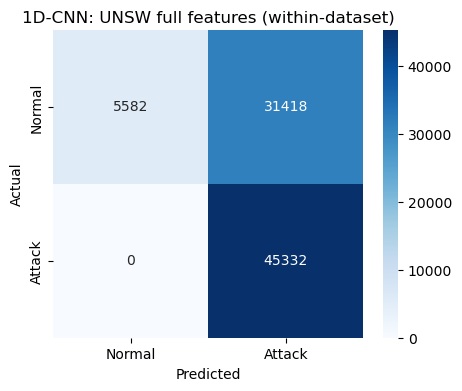

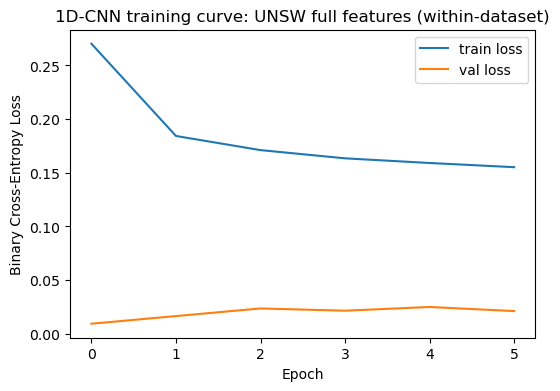

In [8]:
X_unsw_train_fs = unsw_train[unsw_feature_cols]
y_unsw_train_fs = unsw_train["label"]
X_unsw_test_fs = unsw_test[unsw_feature_cols]
y_unsw_test_fs = unsw_test["label"]

cnn_unsw_full, unsw_cnn_scaler, _ = train_and_evaluate_cnn(
    X_unsw_train_fs, y_unsw_train_fs, X_unsw_test_fs, y_unsw_test_fs,
    unsw_feature_cols, "UNSW full features (within-dataset)"
)

1D-CNN - CICIDS full features (within-dataset)
  accuracy          : 0.979
  balanced_accuracy : 0.9624
  precision         : 0.9383
  recall            : 0.9374
  f1                : 0.9378
  roc_auc           : 0.9966
  epochs run (early stopping): 6 / 30
  train time (s)             : 689.44

              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99    419001
      Attack       0.94      0.94      0.94     85148

    accuracy                           0.98    504149
   macro avg       0.96      0.96      0.96    504149
weighted avg       0.98      0.98      0.98    504149



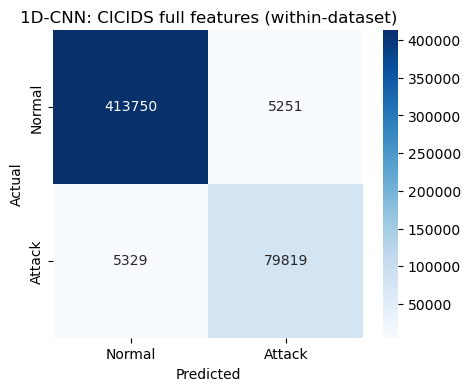

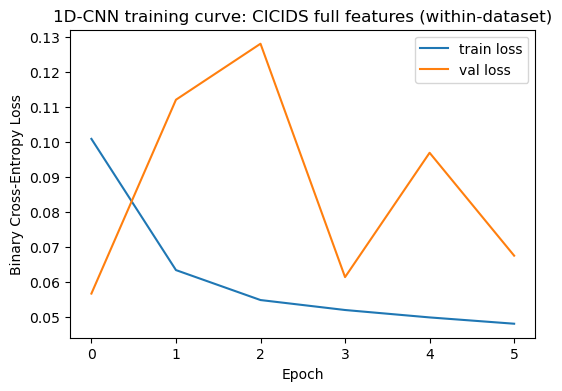

In [9]:
X_cic_train_fs = cic_train[cic_feature_cols]
y_cic_train_fs = cic_train["label"]
X_cic_test_fs = cic_test[cic_feature_cols]
y_cic_test_fs = cic_test["label"]

cnn_cic_full, cic_cnn_scaler, _ = train_and_evaluate_cnn(
    X_cic_train_fs, y_cic_train_fs, X_cic_test_fs, y_cic_test_fs,
    cic_feature_cols, "CICIDS full features (within-dataset)"
)

# 7. Within-Dataset: Harmonized Features (reused for cross-dataset below)

1D-CNN - UNSW harmonized (within-dataset)
  accuracy          : 0.807
  balanced_accuracy : 0.7866
  precision         : 0.745
  recall            : 0.9873
  f1                : 0.8492
  roc_auc           : 0.9496
  epochs run (early stopping): 15 / 30
  train time (s)             : 85.08

              precision    recall  f1-score   support

      Normal       0.97      0.59      0.73     37000
      Attack       0.75      0.99      0.85     45332

    accuracy                           0.81     82332
   macro avg       0.86      0.79      0.79     82332
weighted avg       0.85      0.81      0.80     82332



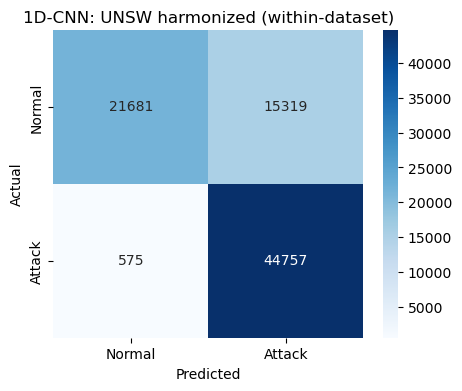

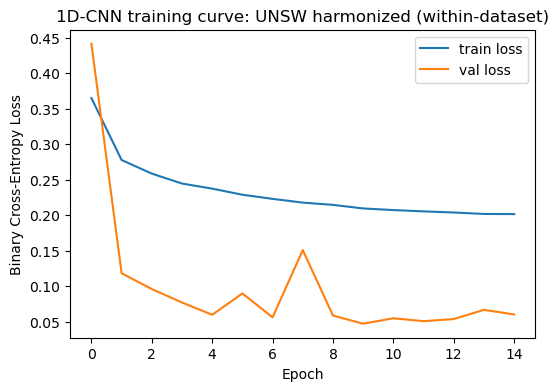

In [10]:
X_unsw_train_h = unsw_train_harm[common_feature_cols]
y_unsw_train_h = unsw_train_harm["label"]
X_unsw_test_h = unsw_test_harm[common_feature_cols]
y_unsw_test_h = unsw_test_harm["label"]

cnn_unsw_harm, unsw_harm_cnn_scaler, _ = train_and_evaluate_cnn(
    X_unsw_train_h, y_unsw_train_h, X_unsw_test_h, y_unsw_test_h,
    common_feature_cols, "UNSW harmonized (within-dataset)"
)

1D-CNN - CICIDS harmonized (within-dataset)
  accuracy          : 0.9559
  balanced_accuracy : 0.8951
  precision         : 0.9255
  recall            : 0.8033
  f1                : 0.8601
  roc_auc           : 0.9878
  epochs run (early stopping): 8 / 30
  train time (s)             : 483.28

              precision    recall  f1-score   support

      Normal       0.96      0.99      0.97    419001
      Attack       0.93      0.80      0.86     85148

    accuracy                           0.96    504149
   macro avg       0.94      0.90      0.92    504149
weighted avg       0.96      0.96      0.95    504149



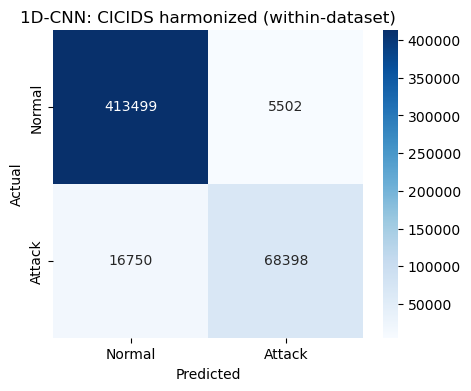

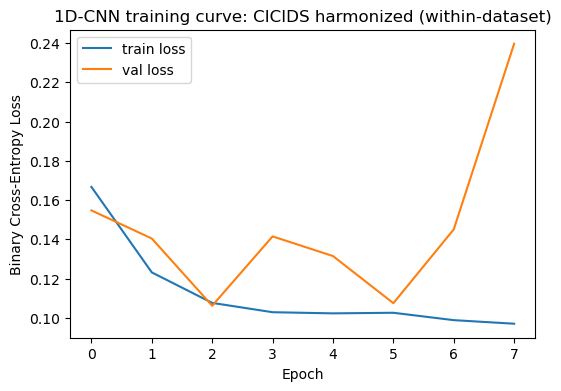

In [16]:
X_cic_train_h = cic_train_harm[common_feature_cols]
y_cic_train_h = cic_train_harm["label"]
X_cic_test_h = cic_test_harm[common_feature_cols]
y_cic_test_h = cic_test_harm["label"]

cnn_cic_harm, cic_harm_cnn_scaler, _ = train_and_evaluate_cnn(
    X_cic_train_h, y_cic_train_h, X_cic_test_h, y_cic_test_h,
    common_feature_cols, "CICIDS harmonized (within-dataset)"
)

# 8. Cross-Dataset Evaluation

Reusing the harmonized models fitted above. Each model's test input must be
scaled with *that model's own* fitted scaler (the one fit on its own
training data), not the other dataset's scaler — same rule as Notebook 4's
SVM cross-dataset section.

1D-CNN - Train UNSW, test CICIDS (cross-dataset)
  accuracy          : 0.719
  balanced_accuracy : 0.6393
  precision         : 0.305
  recall            : 0.519
  f1                : 0.3842
  roc_auc           : 0.7368

              precision    recall  f1-score   support

      Normal       0.89      0.76      0.82    419001
      Attack       0.31      0.52      0.38     85148

    accuracy                           0.72    504149
   macro avg       0.60      0.64      0.60    504149
weighted avg       0.79      0.72      0.74    504149



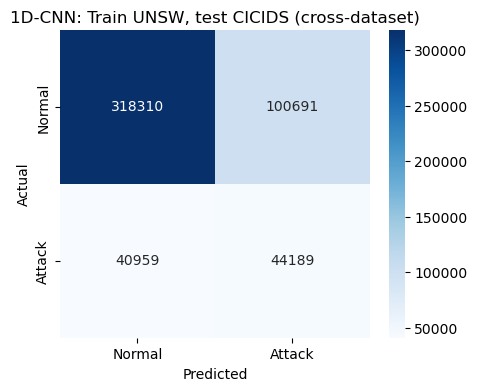

{'model': '1D-CNN',
 'experiment': 'Train UNSW, test CICIDS (cross-dataset)',
 'accuracy': 0.7190314768054682,
 'balanced_accuracy': 0.6393274497608238,
 'precision': 0.30500414135836557,
 'recall': 0.518966975149152,
 'f1': 0.38420540108160744,
 'roc_auc': 0.7368426686999586}

In [17]:
def evaluate_cnn_cross(model, scaler, X_test_df, y_test, feature_order, experiment_name):
    X_test_df = X_test_df[feature_order]
    X_test_scaled = scaler.transform(X_test_df)
    X_test_cnn = X_test_scaled.reshape(X_test_scaled.shape[0], X_test_scaled.shape[1], 1)

    y_proba = model.predict(X_test_cnn, verbose=0).ravel()
    y_pred = (y_proba >= 0.5).astype(int)
    y_test_arr = y_test.values

    metrics = {
        "model": "1D-CNN",
        "experiment": experiment_name,
        "accuracy": accuracy_score(y_test_arr, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_test_arr, y_pred),
        "precision": precision_score(y_test_arr, y_pred, zero_division=0),
        "recall": recall_score(y_test_arr, y_pred, zero_division=0),
        "f1": f1_score(y_test_arr, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test_arr, y_proba),
    }

    print(f"1D-CNN - {experiment_name}")
    for k in ["accuracy", "balanced_accuracy", "precision", "recall", "f1", "roc_auc"]:
        print(f"  {k:18s}: {round(metrics[k], 4)}")
    print()
    print(classification_report(y_test_arr, y_pred, target_names=["Normal", "Attack"], zero_division=0))

    cm = confusion_matrix(y_test_arr, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"])
    plt.title(f"1D-CNN: {experiment_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    all_cnn_results.append(metrics)
    return metrics

evaluate_cnn_cross(cnn_unsw_harm, unsw_harm_cnn_scaler, X_cic_test_h, y_cic_test_h, common_feature_cols, "Train UNSW, test CICIDS (cross-dataset)")

1D-CNN - Train CICIDS, test UNSW (cross-dataset)
  accuracy          : 0.4502
  balanced_accuracy : 0.5007
  precision         : 1.0
  recall            : 0.0015
  f1                : 0.003
  roc_auc           : 0.6671

              precision    recall  f1-score   support

      Normal       0.45      1.00      0.62     37000
      Attack       1.00      0.00      0.00     45332

    accuracy                           0.45     82332
   macro avg       0.72      0.50      0.31     82332
weighted avg       0.75      0.45      0.28     82332



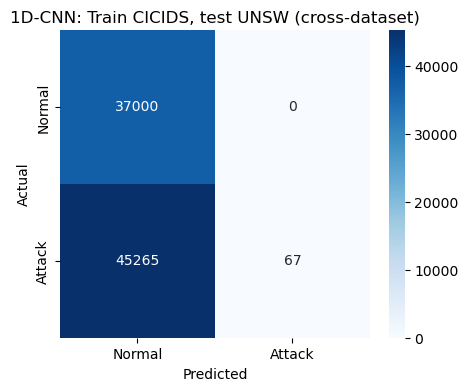

{'model': '1D-CNN',
 'experiment': 'Train CICIDS, test UNSW (cross-dataset)',
 'accuracy': 0.4502137686440266,
 'balanced_accuracy': 0.5007389923233037,
 'precision': 1.0,
 'recall': 0.001477984646607253,
 'f1': 0.0029516068635873035,
 'roc_auc': 0.6670791750234307}

In [18]:
evaluate_cnn_cross(cnn_cic_harm, cic_harm_cnn_scaler, X_unsw_test_h, y_unsw_test_h, common_feature_cols, "Train CICIDS, test UNSW (cross-dataset)")

# 9. Results Table and Comparison with Classical Models

In [19]:
cnn_results_df = pd.DataFrame(all_cnn_results)
cnn_results_df.to_csv(os.path.join(PROCESSED_DIR, "cnn_results.csv"), index=False)
cnn_results_df

,model,experiment,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,train_seconds,predict_seconds,epochs_run
0,1D-CNN,UNSW full features (within-dataset),0.570495,0.522135,0.561777,1.000000,0.719407,0.941776,50.02,11.5216,6.0
1,1D-CNN,UNSW full features (within-dataset),0.618399,0.575432,0.590645,1.000000,0.742648,0.941724,48.88,10.9852,6.0
2,1D-CNN,CICIDS full features (within-dataset),0.979014,0.962441,0.938274,0.937415,0.937844,0.996590,689.44,72.2016,6.0
3,1D-CNN,UNSW harmonized (within-dataset),0.806952,0.786644,0.745006,0.987316,0.849214,0.949553,85.08,11.0472,15.0
4,1D-CNN,CICIDS harmonized (within-dataset),0.965722,0.905804,0.978078,0.815322,0.889314,0.993630,4501.31,64.3082,22.0
5,1D-CNN,"Train UNSW, test CICIDS (cross-dataset)",0.719031,0.639327,0.305004,0.518967,0.384205,0.736843,NaN,NaN,NaN
6,1D-CNN,"Train CICIDS, test UNSW (cross-dataset)",0.449400,0.500000,0.000000,0.000000,0.000000,0.580172,NaN,NaN,NaN
7,1D-CNN,CICIDS harmonized (within-dataset),0.955862,0.895076,0.925548,0.803284,0.860093,0.987847,483.28,62.2520,8.0
8,1D-CNN,"Train UNSW, test CICIDS (cross-dataset)",0.719031,0.639327,0.305004,0.518967,0.384205,0.736843,NaN,NaN,NaN
9,1D-CNN,"Train CICIDS, test UNSW (cross-dataset)",0.450214,0.500739,1.000000,0.001478,0.002952,0.667079,NaN,NaN,NaN


In [21]:
classical_results_path = os.path.join(PROCESSED_DIR, "classical_ml_results.csv")

if os.path.exists(classical_results_path):
    classical_results_df = pd.read_csv(classical_results_path)

    combined = pd.concat(
        [classical_results_df, cnn_results_df],
        ignore_index=True
    )

    combined.to_csv(
        os.path.join(PROCESSED_DIR, "all_model_results.csv"),
        index=False
    )

    print("Combined results (all models) saved successfully!")

    within = combined[
        combined["experiment"].str.contains("within-dataset", case=False, na=False)
    ]

    comparison = within.pivot_table(
        index="experiment",
        columns="model",
        values="f1",
        aggfunc="mean"
    )

    display(comparison)

else:
    print("classical_ml_results.csv not found. Run Notebook 4 first.")


Combined results (all models) saved successfully!


model,1D-CNN,Random Forest,SVM,XGBoost
experiment,,,,
CICIDS full features (within-dataset),0.937844,0.995899,0.896829,0.997612
CICIDS harmonized (within-dataset),0.874704,0.986859,0.722827,0.988784
UNSW full features (within-dataset),0.731028,0.888528,0.855367,0.888695
UNSW harmonized (within-dataset),0.849214,0.889919,0.780586,0.887613


# 10. Saving the Model

Only the full-feature UNSW-NB15 model is saved for Notebook 6's XAI pass,
matching that notebook's stated scope (explainability on the full
UNSW-NB15 feature set, not the harmonized cross-dataset set).

In [22]:
cnn_unsw_full.save(os.path.join(MODELS_DIR, "cnn_unsw_full.keras"))

import joblib
joblib.dump(unsw_cnn_scaler, os.path.join(MODELS_DIR, "unsw_cnn_scaler.joblib"))

print("1D-CNN (UNSW full-feature) model and scaler saved.")

1D-CNN (UNSW full-feature) model and scaler saved.


# 11. Summary

**Fill in after running on the full datasets:**

- Report the actual within-dataset F1/ROC-AUC for the 1D-CNN on UNSW-NB15
  and CICIDS2017 (full features), and compare directly against Random
  Forest, XGBoost, and SVM from Notebook 4's results table.
- State how many epochs early stopping actually ran for in each experiment
  (printed above) - if it consistently stops very early (e.g. 2-3 epochs),
  that is worth discussing as a sign the model converges quickly on this
  data, not necessarily a problem.
- Report the cross-dataset harmonized-feature F1/ROC-AUC for both
  directions and compare the size of the drop against Random Forest/XGBoost/
  SVM's cross-dataset drop from Notebook 4 - do all four models collapse by
  a similar margin (pointing to a genuine dataset-level distribution-shift
  effect, consistent with Notebook 3's KS statistics), or does the 1D-CNN
  behave differently?
- State plainly whether the added training time/complexity of the 1D-CNN
  was justified by better detection or generalization performance relative
  to the classical models - a "no, it was not justified" conclusion is a
  legitimate research finding, not a failure of this notebook.
